# Federated Learning with Swin Transformer V2
## CheXpert Multi-Label Classification

In [1]:
!pip install timm albumentations -q

## Configuration

In [2]:
# Training Configuration
NUM_ROUNDS = 15  # Number of federated rounds to run
START_ROUND = 1  # Starting round (change to continue from checkpoint)
NUM_CLIENTS = 3  # Number of federated clients

# Path to global model from previous training (None for first run)
GLOBAL_MODEL_PATH = None  # Example: '/kaggle/input/round-5-model/global_model_round_5.pth'

print(f"Configuration:")
print(f"  Rounds: {NUM_ROUNDS} (starting from round {START_ROUND})")
print(f"  Clients: {NUM_CLIENTS}")
print(f"  Global model: {GLOBAL_MODEL_PATH if GLOBAL_MODEL_PATH else 'None (training from scratch)'}")

Configuration:
  Rounds: 15 (starting from round 1)
  Clients: 3
  Global model: None (training from scratch)


## Import Libraries

In [3]:
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd
import numpy as np
import cv2
from tqdm import tqdm
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import roc_auc_score
import albumentations as A
from albumentations.pytorch import ToTensorV2
import timm
import copy
from collections import OrderedDict
import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully")
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")

Libraries imported successfully
PyTorch version: 2.10.0+cu128
CUDA available: True
GPU: Tesla T4
GPU Memory: 15.64 GB


## Configuration Class

In [4]:
class Config:
    # Paths
    DATA_PATH = '/kaggle/input/datasets/ashery/chexpert/train.csv'
    IMAGE_ROOT = '/kaggle/input/datasets/ashery/chexpert/'
    CHECKPOINT_DIR = '/kaggle/working/checkpoints'
    
    # Model Architecture
    MODEL_NAME = 'swinv2_tiny_window8_256'
    IMG_SIZE = 256
    NUM_CLASSES = 14
    DROP_PATH_RATE = 0.2
    
    # Training Hyperparameters
    BATCH_SIZE = 32
    NUM_WORKERS = 2
    WEIGHT_DECAY = 0.01
    USE_AMP = True
    
    # Learning Rate Schedule (per round)
    LR_SCHEDULE = {
        1: 1e-4,   # Rounds 1-5
        6: 5e-5,   # Rounds 6-10
        11: 2e-5,  # Rounds 11-15
        16: 1e-5   # Rounds 16+
    }
    
    # Focal Loss Parameters
    FOCAL_ALPHA = 0.25
    FOCAL_GAMMA = 2.0
    
    # Label Strategy (U-Zeros for low-AUROC diseases)
    UNCERTAIN_STRATEGY = {
        'Consolidation': 'zeros',
        'Enlarged Cardiomediastinum': 'zeros',
        'Lung Lesion': 'zeros',
        'Fracture': 'zeros',
        'Pleural Other': 'zeros',
    }
    
    # Disease Labels
    DISEASES = [
        'No Finding', 'Enlarged Cardiomediastinum', 'Cardiomegaly',
        'Lung Opacity', 'Lung Lesion', 'Edema', 'Consolidation',
        'Pneumonia', 'Atelectasis', 'Pneumothorax', 'Pleural Effusion',
        'Pleural Other', 'Fracture', 'Support Devices'
    ]
    
    # Global Validation Split
    GLOBAL_VAL_SIZE = 0.10  # 10% of data for global validation
     # 15% of each client's data for local validation
    
    @classmethod
    def get_lr_for_round(cls, round_num):
        for threshold in sorted(cls.LR_SCHEDULE.keys(), reverse=True):
            if round_num >= threshold:
                return cls.LR_SCHEDULE[threshold]
        return 1e-4

# Update configuration

Config.NUM_ROUNDS = NUM_ROUNDS
Config.START_ROUND = START_ROUND
Config.NUM_CLIENTS = NUM_CLIENTS
Config.GLOBAL_MODEL_PATH = GLOBAL_MODEL_PATH

print("Configuration loaded successfully")

Configuration loaded successfully


## Dataset Class

In [5]:
class CheXpertDataset(torch.utils.data.Dataset):
    """CheXpert dataset with flexible label handling"""
    
    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform
        
    def __len__(self):
        return len(self.df)
    
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        
        # Load image
        img_path = row['Path'].replace('CheXpert-v1.0-small/', Config.IMAGE_ROOT)
        image = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        
        if image is None:
            image = np.zeros((Config.IMG_SIZE, Config.IMG_SIZE), dtype=np.uint8)
        
        # Convert to RGB
        image = cv2.cvtColor(image, cv2.COLOR_GRAY2RGB)
        
        # Apply transformations
        if self.transform:
            image = self.transform(image=image)['image']
        
        # Process labels with disease-specific uncertain strategy
        labels = []
        for disease in Config.DISEASES:
            label = row[disease]
            
            if pd.isna(label):
                label = 0.0
            elif label == -1:
                strategy = Config.UNCERTAIN_STRATEGY.get(disease, 'ones')
                label = 0.0 if strategy == 'zeros' else 1.0
            else:
                label = float(label)
            
            labels.append(label)
        
        return image, torch.tensor(labels, dtype=torch.float32)

print("Dataset class defined")

Dataset class defined


## Data Augmentation

In [6]:
def get_transforms(mode='train'):
    """Get augmentation pipeline"""
    
    if mode == 'train':
        return A.Compose([
            A.Resize(Config.IMG_SIZE, Config.IMG_SIZE),
            A.HorizontalFlip(p=0.5),
            A.ShiftScaleRotate(
                shift_limit=0.1, 
                scale_limit=0.1, 
                rotate_limit=10, 
                p=0.5
            ),
            A.OneOf([
                A.CLAHE(clip_limit=2.0, p=1.0),
                A.RandomBrightnessContrast(p=1.0),
            ], p=0.5),
            A.GaussNoise(var_limit=(10.0, 30.0), p=0.2),
            A.CoarseDropout(
                max_holes=8, 
                max_height=16, 
                max_width=16, 
                p=0.3
            ),
            A.Normalize(
                mean=[0.485, 0.456, 0.406], 
                std=[0.229, 0.224, 0.225]
            ),
            ToTensorV2(),
        ])
    else:
        return A.Compose([
            A.Resize(Config.IMG_SIZE, Config.IMG_SIZE),
            A.Normalize(
                mean=[0.485, 0.456, 0.406], 
                std=[0.229, 0.224, 0.225]
            ),
            ToTensorV2(),
        ])

print("Augmentation pipeline defined")

Augmentation pipeline defined


## Model Architecture

In [7]:
class FocalLoss(nn.Module):
    """Focal Loss for handling class imbalance"""
    
    def __init__(self, alpha=0.25, gamma=2.0):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
    
    def forward(self, inputs, targets):
        bce_loss = F.binary_cross_entropy_with_logits(
            inputs, targets, reduction='none'
        )
        pt = torch.exp(-bce_loss)
        focal_loss = self.alpha * (1 - pt) ** self.gamma * bce_loss
        return focal_loss.mean()


class SwinTransformerV2(nn.Module):
    """Swin Transformer V2 for multi-label classification"""
    
    def __init__(self):
        super().__init__()
        
        # Backbone
        self.backbone = timm.create_model(
            Config.MODEL_NAME,
            pretrained=True,
            num_classes=0,
            drop_path_rate=Config.DROP_PATH_RATE
        )
        
        # Classification head
        self.feature_dim = self.backbone.num_features
        self.head = nn.Sequential(
            nn.Linear(self.feature_dim, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(512, Config.NUM_CLASSES)
        )
    
    def forward(self, x):
        features = self.backbone(x)
        return self.head(features)

print("Model architecture defined")

Model architecture defined


## Training and Validation Functions

In [8]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    """Train model for one epoch"""
    
    model.train()
    total_loss = 0
    scaler = torch.cuda.amp.GradScaler() if Config.USE_AMP else None
    
    pbar = tqdm(loader, desc='Training', leave=False)
    for images, labels in pbar:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        
        if Config.USE_AMP:
            with torch.cuda.amp.autocast():
                outputs = model(images)
                loss = criterion(outputs, labels)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
        
        total_loss += loss.item()
        pbar.set_postfix({'loss': f'{total_loss / (pbar.n + 1):.4f}'})
    
    return total_loss / len(loader)


@torch.no_grad()
def validate(model, loader, device):
    """Validate model and compute per-disease AUROC"""
    
    model.eval()
    all_preds, all_labels = [], []
    
    for images, labels in tqdm(loader, desc='Validating', leave=False):
        images = images.to(device)
        
        if Config.USE_AMP:
            with torch.cuda.amp.autocast():
                outputs = model(images)
        else:
            outputs = model(images)
        
        probs = torch.sigmoid(outputs)
        all_preds.append(probs.cpu().numpy())
        all_labels.append(labels.numpy())
    
    all_preds = np.concatenate(all_preds)
    all_labels = np.concatenate(all_labels)
    
    # Calculate AUROC per disease
    aurocs = {}
    for i, disease in enumerate(Config.DISEASES):
        try:
            if len(np.unique(all_labels[:, i])) > 1:
                auroc = roc_auc_score(all_labels[:, i], all_preds[:, i])
                aurocs[disease] = auroc
            else:
                aurocs[disease] = 0.5
        except:
            aurocs[disease] = 0.5
    
    mean_auroc = np.mean(list(aurocs.values()))
    return mean_auroc, aurocs

print("Training and validation functions defined")

Training and validation functions defined


## Federated Averaging

In [9]:
def federated_averaging(client_models, client_weights):
    """Perform weighted federated averaging"""
    
    global_model_state = OrderedDict()
    keys = client_models[0].keys()
    
    for key in keys:
        param_stack = torch.stack([
            client_models[i][key].float() * client_weights[i]
            for i in range(len(client_models))
        ])
        global_model_state[key] = param_stack.sum(dim=0)
    
    return global_model_state

print("Federated averaging function defined")

Federated averaging function defined


## Data Loading and Preparation

In [10]:
print("=" * 80)
print("DATA PREPARATION")
print("=" * 80)

# Load dataset
df = pd.read_csv(Config.DATA_PATH)
print(f"\nTotal dataset: {len(df):,} images")

# Filter: Frontal images only (exclude Lateral)
df_frontal = df[df['Frontal/Lateral'] == 'Frontal'].copy()
print(f"Frontal images: {len(df_frontal):,} images")
print(f"Excluded lateral: {len(df) - len(df_frontal):,} images")

# Extract patient IDs
df_frontal['Patient'] = df_frontal['Path'].apply(lambda x: x.split('/')[2])
unique_patients = df_frontal['Patient'].unique()
print(f"Unique patients: {len(unique_patients):,}")

# Create global validation set (patient-level split)
np.random.seed(42)
np.random.shuffle(unique_patients)

global_val_size = int(len(unique_patients) * Config.GLOBAL_VAL_SIZE)
global_val_patients = unique_patients[:global_val_size]
train_patients = unique_patients[global_val_size:]

global_val_df = df_frontal[df_frontal['Patient'].isin(global_val_patients)].copy()
train_df = df_frontal[df_frontal['Patient'].isin(train_patients)].copy()

print(f"\nGlobal validation set:")
print(f"  Patients: {len(global_val_patients):,}")
print(f"  Images: {len(global_val_df):,}")

print(f"\nTraining pool:")
print(f"  Patients: {len(train_patients):,}")
print(f"  Images: {len(train_df):,}")

# Create global validation dataloader
global_val_dataset = CheXpertDataset(global_val_df, get_transforms('val'))
global_val_loader = torch.utils.data.DataLoader(
    global_val_dataset,
    batch_size=Config.BATCH_SIZE,
    shuffle=False,
    num_workers=Config.NUM_WORKERS,
    pin_memory=True
)

print(f"\nGlobal validation loader: {len(global_val_loader)} batches")

# Split training data across clients (patient-level)
client_patient_splits = np.array_split(train_patients, Config.NUM_CLIENTS)

client_loaders = []
for client_id in range(Config.NUM_CLIENTS):
    client_patients = client_patient_splits[client_id]
    client_df = train_df[train_df['Patient'].isin(client_patients)].copy()
    
    
    # Use 100% of client data for training
    client_train_df = client_df.reset_index(drop=True)
    
    # Create dataset
    train_dataset = CheXpertDataset(client_train_df, get_transforms('train'))
    
    # Create dataloader (No val_loader needed)
    train_loader = torch.utils.data.DataLoader(
        train_dataset,
        batch_size=Config.BATCH_SIZE,
        shuffle=True,
        num_workers=Config.NUM_WORKERS,
        pin_memory=True
    )
    
    client_loaders.append({
        'train': train_loader,
        'train_size': len(train_dataset),
        'num_patients': len(client_patients)
    })
    
    print(f"\nClient {client_id}:")
    print(f"  Patients: {len(client_patients):,}")
    print(f"  Train images: {len(train_dataset):,}")
  

print(f"\n{'=' * 80}")
print("DATA PREPARATION COMPLETE")
print(f"{'=' * 80}")

DATA PREPARATION

Total dataset: 223,414 images
Frontal images: 191,027 images
Excluded lateral: 32,387 images
Unique patients: 64,534

Global validation set:
  Patients: 6,453
  Images: 19,099

Training pool:
  Patients: 58,081
  Images: 171,928

Global validation loader: 597 batches

Client 0:
  Patients: 19,361
  Train images: 57,650

Client 1:
  Patients: 19,360
  Train images: 56,304

Client 2:
  Patients: 19,360
  Train images: 57,974

DATA PREPARATION COMPLETE


## Initialize Global Model

In [11]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"\nDevice: {device}")

# Build global model
global_model = SwinTransformerV2().to(device)

# Load from checkpoint if continuing training
if Config.START_ROUND > 1 and Config.GLOBAL_MODEL_PATH:
    try:
        checkpoint = torch.load(Config.GLOBAL_MODEL_PATH, map_location=device)
        global_model.load_state_dict(checkpoint['model_state_dict'])
        prev_auroc = checkpoint.get('mean_auroc', 0.0)
        print(f"Loaded global model from round {Config.START_ROUND - 1}")
        print(f"Previous AUROC: {prev_auroc:.4f}")
    except Exception as e:
        print(f"Warning: Could not load global model: {e}")
        print("Starting from pretrained ImageNet weights")
else:
    print("Starting from pretrained ImageNet weights")

# Count parameters
total_params = sum(p.numel() for p in global_model.parameters())
trainable_params = sum(p.numel() for p in global_model.parameters() if p.requires_grad)

print(f"\nModel parameters:")
print(f"  Total: {total_params:,}")
print(f"  Trainable: {trainable_params:,}")

print("\nGlobal model initialized successfully")


Device: cuda


model.safetensors:   0%|          | 0.00/115M [00:00<?, ?B/s]

Starting from pretrained ImageNet weights

Model parameters:
  Total: 27,980,088
  Trainable: 27,980,088

Global model initialized successfully


## Federated Training Loop

In [12]:
print(f"\n{'=' * 80}")
print(f"FEDERATED TRAINING: {Config.NUM_ROUNDS} ROUNDS")
print(f"{'=' * 80}\n")

# Storage for results
round_results = []

# Training loop
for round_num in range(Config.START_ROUND, Config.START_ROUND + Config.NUM_ROUNDS):
    print(f"\n{'=' * 80}")
    print(f"ROUND {round_num}/{Config.START_ROUND + Config.NUM_ROUNDS - 1}")
    print(f"{'=' * 80}")
    
    # Get learning rate for this round
    lr = Config.get_lr_for_round(round_num)
    criterion = FocalLoss(Config.FOCAL_ALPHA, Config.FOCAL_GAMMA)
    
    print(f"\nLearning rate: {lr:.6f}")
    
    # Storage for client models and metrics
    client_models = []
    client_metrics = []
    client_aurocs = []
    
    # Train each client
    for client_id in range(Config.NUM_CLIENTS):
        print(f"\n{'-' * 80}")
        print(f"CLIENT {client_id}")
        print(f"{'-' * 80}")
        
        # Create local model (copy of global model)
        local_model = copy.deepcopy(global_model)
        optimizer = torch.optim.AdamW(
            local_model.parameters(),
            lr=lr,
            weight_decay=Config.WEIGHT_DECAY
        )
        
        # Get client data (No local validation loader)
        train_loader = client_loaders[client_id]['train']
        
        print(f"Train: {client_loaders[client_id]['train_size']:,} images")
        
        # Train for 1 local epoch
        train_loss = train_one_epoch(
            local_model, train_loader, criterion, optimizer, device
        )
        print(f"  Train loss: {train_loss:.4f}")
            
        # Validate local model on GLOBAL validation set only
        global_mean_auroc, global_auroc_per_disease = validate(
            local_model, global_val_loader, device
        )
        print(f"Global val AUROC: {global_mean_auroc:.4f}")
        
        # Display per-disease AUROC on global validation
        print(f"\nPer-disease AUROC (global validation):")
        for disease, auroc in global_auroc_per_disease.items():
            print(f"  {disease:30s}: {auroc:.4f}")
            
        # Store results (CRITICAL: Saves weights for Federated Averaging)
        client_models.append(local_model.state_dict())
        client_aurocs.append(global_mean_auroc)
        client_metrics.append({
            'client_id': client_id,
            'train_loss': train_loss,
            'global_auroc': global_mean_auroc,
            'auroc_per_disease': global_auroc_per_disease
        })
        
        # Store results (CRITICAL: You accidentally deleted this block)
        client_models.append(local_model.state_dict())
        client_aurocs.append(global_mean_auroc)
        client_metrics.append({
            'client_id': client_id,
            'train_loss': train_loss,
            'global_auroc': global_mean_auroc,
            'auroc_per_disease': global_auroc_per_disease
        })
    

    
    # Federated averaging
    print(f"\n{'-' * 80}")
    print("FEDERATED AVERAGING")
    print(f"{'-' * 80}")
    
    # Calculate weights based on global validation AUROC
    total_auroc = sum(client_aurocs)
    client_weights = [auroc / total_auroc for auroc in client_aurocs]
    
    print("\nClient weights (based on global val AUROC):")
    for i, (auroc, weight) in enumerate(zip(client_aurocs, client_weights)):
        print(f"  Client {i}: AUROC={auroc:.4f}, Weight={weight:.4f}")
    
    # Perform averaging
    global_model_state = federated_averaging(client_models, client_weights)
    global_model.load_state_dict(global_model_state)
    
    print("\nFederated averaging complete")
    
    # Evaluate global model on global validation set
    print(f"\n{'-' * 80}")
    print("GLOBAL MODEL EVALUATION")
    print(f"{'-' * 80}")
    
    global_model_auroc, global_model_disease_aurocs = validate(
        global_model, global_val_loader, device
    )
    
    print(f"\nGlobal model AUROC: {global_model_auroc:.4f}")
    print(f"\nPer-disease AUROC:")
    for disease, auroc in global_model_disease_aurocs.items():
        print(f"  {disease:30s}: {auroc:.4f}")
    
    # Save checkpoint
    os.makedirs(Config.CHECKPOINT_DIR, exist_ok=True)
    
    checkpoint = {
        'model_state_dict': global_model.state_dict(),
        'round': round_num,
        'mean_auroc': global_model_auroc,
        'auroc_per_disease': global_model_disease_aurocs,
        'client_metrics': client_metrics,
        'config': {
            'model_name': Config.MODEL_NAME,
            'img_size': Config.IMG_SIZE,
            'num_clients': Config.NUM_CLIENTS,
            'learning_rate': lr,
        }
    }
    
    save_path = f'{Config.CHECKPOINT_DIR}/global_model_round_{round_num}.pth'
    torch.save(checkpoint, save_path)
    
    print(f"\nCheckpoint saved: {save_path}")
    print(f"Size: {os.path.getsize(save_path) / 1e6:.2f} MB")
    
    # Store round results
    round_results.append({
        'round': round_num,
        'global_auroc': global_model_auroc,
        'client_aurocs': client_aurocs,
        'learning_rate': lr
    })
    
    # Check if target reached
    if global_model_auroc >= 0.85:
        print(f"\n{'=' * 80}")
        print("TARGET AUROC REACHED (>= 0.85)")
        print(f"{'=' * 80}")
        print(f"Final AUROC: {global_model_auroc:.4f}")
        print(f"Rounds completed: {round_num}")
        break

print(f"\n{'=' * 80}")
print("TRAINING COMPLETE")
print(f"{'=' * 80}")


FEDERATED TRAINING: 15 ROUNDS


ROUND 1/15

Learning rate: 0.000100

--------------------------------------------------------------------------------
CLIENT 0
--------------------------------------------------------------------------------
Train: 57,650 images


  Train loss: 0.0257


Global val AUROC: 0.7388

Per-disease AUROC (global validation):
  No Finding                    : 0.8609
  Enlarged Cardiomediastinum    : 0.5966
  Cardiomegaly                  : 0.8020
  Lung Opacity                  : 0.6988
  Lung Lesion                   : 0.7143
  Edema                         : 0.8091
  Consolidation                 : 0.6914
  Pneumonia                     : 0.7077
  Atelectasis                   : 0.6827
  Pneumothorax                  : 0.7369
  Pleural Effusion              : 0.8380
  Pleural Other                 : 0.7391
  Fracture                      : 0.6441
  Support Devices               : 0.8222

--------------------------------------------------------------------------------
CLIENT 1
--------------------------------------------------------------------------------
Train: 56,304 images


  Train loss: 0.0256


Global val AUROC: 0.7395

Per-disease AUROC (global validation):
  No Finding                    : 0.8618
  Enlarged Cardiomediastinum    : 0.5992
  Cardiomegaly                  : 0.7966
  Lung Opacity                  : 0.6942
  Lung Lesion                   : 0.7304
  Edema                         : 0.8136
  Consolidation                 : 0.6590
  Pneumonia                     : 0.6993
  Atelectasis                   : 0.6757
  Pneumothorax                  : 0.7660
  Pleural Effusion              : 0.8409
  Pleural Other                 : 0.7650
  Fracture                      : 0.6288
  Support Devices               : 0.8220

--------------------------------------------------------------------------------
CLIENT 2
--------------------------------------------------------------------------------
Train: 57,974 images


...

  Train loss: 0.0204


Global val AUROC: 0.8092

Per-disease AUROC (global validation):
  No Finding                    : 0.8890
  Enlarged Cardiomediastinum    : 0.7053
  Cardiomegaly                  : 0.8688
  Lung Opacity                  : 0.7366
  Lung Lesion                   : 0.7994
  Edema                         : 0.8533
  Consolidation                 : 0.7442
  Pneumonia                     : 0.7655
  Atelectasis                   : 0.7255
  Pneumothorax                  : 0.8600
  Pleural Effusion              : 0.8772
  Pleural Other                 : 0.8207
  Fracture                      : 0.7835
  Support Devices               : 0.8992

--------------------------------------------------------------------------------
CLIENT 2
--------------------------------------------------------------------------------
Train: 57,974 images


  Train loss: 0.0204


Global val AUROC: 0.8104

Per-disease AUROC (global validation):
  No Finding                    : 0.8894
  Enlarged Cardiomediastinum    : 0.7063
  Cardiomegaly                  : 0.8689
  Lung Opacity                  : 0.7372
  Lung Lesion                   : 0.8032
  Edema                         : 0.8548
  Consolidation                 : 0.7448
  Pneumonia                     : 0.7645
  Atelectasis                   : 0.7261
  Pneumothorax                  : 0.8602
  Pleural Effusion              : 0.8780
  Pleural Other                 : 0.8222
  Fracture                      : 0.7918
  Support Devices               : 0.8983

--------------------------------------------------------------------------------
FEDERATED AVERAGING
--------------------------------------------------------------------------------

Client weights (based on global val AUROC):
  Client 0: AUROC=0.8108, Weight=0.1668
  Client 1: AUROC=0.8108, Weight=0.1668
  Client 2: AUROC=0.8092, Weight=0.1665
  Client 3: A


Global model AUROC: 0.8124

Per-disease AUROC:
  No Finding                    : 0.8912
  Enlarged Cardiomediastinum    : 0.7114
  Cardiomegaly                  : 0.8708
  Lung Opacity                  : 0.7385
  Lung Lesion                   : 0.8046
  Edema                         : 0.8561
  Consolidation                 : 0.7477
  Pneumonia                     : 0.7667
  Atelectasis                   : 0.7270
  Pneumothorax                  : 0.8657
  Pleural Effusion              : 0.8788
  Pleural Other                 : 0.8252
  Fracture                      : 0.7904
  Support Devices               : 0.8998

Checkpoint saved: /kaggle/working/checkpoints/global_model_round_15.pth
Size: 112.03 MB

TRAINING COMPLETE


## Training Summary

In [14]:
print(f"\n{'=' * 80}")
print("TRAINING SUMMARY")
print(f"{'=' * 80}\n")

print(f"Rounds completed: {len(round_results)}")
print(f"\nAUROC progression:")
for result in round_results:
    print(f"  Round {result['round']:2d}: {result['global_auroc']:.4f} (LR: {result['learning_rate']:.6f})")

final_auroc = round_results[-1]['global_auroc']
print(f"\nFinal global AUROC: {final_auroc:.4f}")






TRAINING SUMMARY

Rounds completed: 15

AUROC progression:
  Round  1: 0.7271 (LR: 0.000100)
  Round  2: 0.7648 (LR: 0.000100)
  Round  3: 0.7794 (LR: 0.000100)
  Round  4: 0.7848 (LR: 0.000100)
  Round  5: 0.7914 (LR: 0.000100)
  Round  6: 0.7975 (LR: 0.000050)
  Round  7: 0.8010 (LR: 0.000050)
  Round  8: 0.8031 (LR: 0.000050)
  Round  9: 0.8053 (LR: 0.000050)
  Round 10: 0.8070 (LR: 0.000050)
  Round 11: 0.8093 (LR: 0.000020)
  Round 12: 0.8097 (LR: 0.000020)
  Round 13: 0.8103 (LR: 0.000020)
  Round 14: 0.8119 (LR: 0.000020)
  Round 15: 0.8124 (LR: 0.000020)

Final global AUROC: 0.8124


In [25]:
from sklearn.metrics import accuracy_score
import numpy as np
import torch

def evaluate_final_model(model, loader, device, threshold=0.5):
    """
    Evaluates the model and displays Global and Per-Class Accuracy.
    """
    model.eval()
    all_targets = []
    all_outputs = []
    
    print("Inference in progress...")
    with torch.no_grad():
        for inputs, targets in loader:
            inputs = inputs.to(device)
            # Use sigmoid for multi-label probabilities
            outputs = torch.sigmoid(model(inputs))
            all_targets.append(targets.cpu().numpy())
            all_outputs.append(outputs.cpu().numpy())
            
    all_targets = np.vstack(all_targets)
    all_outputs = np.vstack(all_outputs)
    
    # Convert probabilities to binary predictions based on threshold
    predictions = (all_outputs > threshold).astype(int)
    
    # 1. Calculate Global Accuracy (All labels combined)
    global_acc = accuracy_score(all_targets.flatten(), predictions.flatten())
    
    print(f"\n{'='*45}")
    print(f"FINAL GLOBAL MODEL ACCURACY: {global_acc:.4f}")
    print(f"{'='*45}")
    
    # 2. Calculate Per-Class Accuracy
    print(f"{'Disease':<30} | {'Accuracy':<8}")
    print("-" * 45)
    
    disease_names = Config.DISEASES
    for i, name in enumerate(disease_names):
        # Extract the specific column for this disease
        class_targets = all_targets[:, i]
        class_preds = predictions[:, i]
        
        # Calculate accuracy for this specific class
        class_acc = accuracy_score(class_targets, class_preds)
        print(f"{name:<30} | {class_acc:.4f}")
    print("-" * 45)

# --- EXECUTION BLOCK ---

target_round = 15 
checkpoint_path = f'{Config.CHECKPOINT_DIR}/global_model_round_{target_round}.pth'

print(f"Loading checkpoint: {checkpoint_path}")
checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
global_model.load_state_dict(checkpoint['model_state_dict'])

evaluate_final_model(global_model, global_val_loader, device, threshold=0.5)

Loading checkpoint: /kaggle/working/checkpoints/global_model_round_15.pth
Inference in progress...

FINAL GLOBAL MODEL ACCURACY: 0.8725
Disease                        | Accuracy
---------------------------------------------
No Finding                     | 0.9169
Enlarged Cardiomediastinum     | 0.9527
Cardiomegaly                   | 0.8749
Lung Opacity                   | 0.6818
Lung Lesion                    | 0.9647
Edema                          | 0.7921
Consolidation                  | 0.9322
Pneumonia                      | 0.8956
Atelectasis                    | 0.7084
Pneumothorax                   | 0.9120
Pleural Effusion               | 0.7994
Pleural Other                  | 0.9854
Fracture                       | 0.9604
Support Devices                | 0.8383
---------------------------------------------


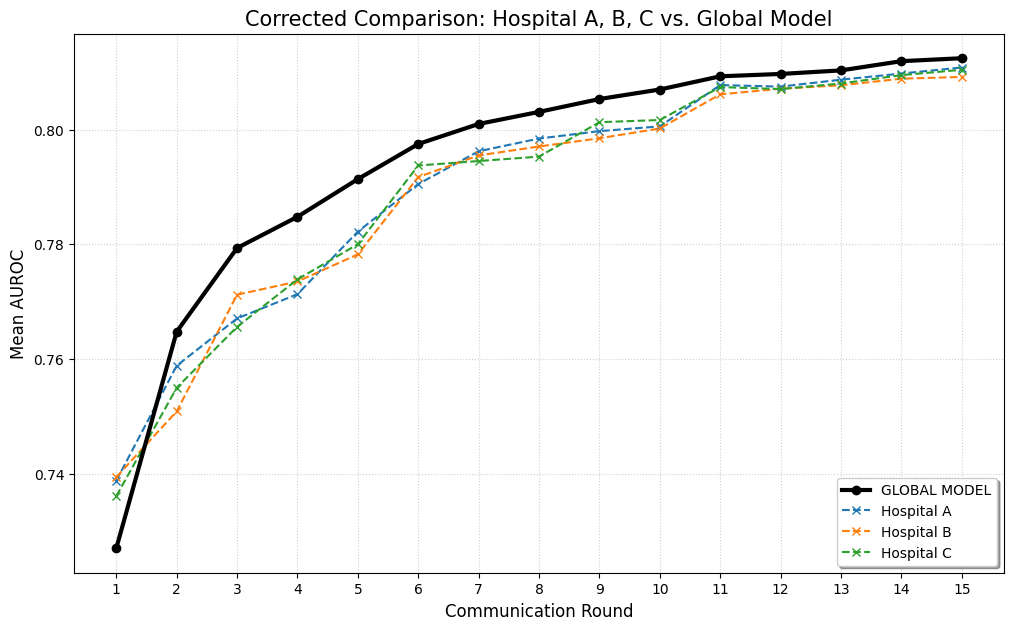

In [31]:
import matplotlib.pyplot as plt

def plot_hospital_comparison_fixed(round_results):
    """
    Plots individual Hospital (A, B, C) scores by skipping the duplicated entries.
    """
    rounds = [r['round'] for r in round_results]
    global_aurocs = [r['global_auroc'] for r in round_results]
    
    plt.figure(figsize=(12, 7))
    
    # 1. Plot the Global Model
    plt.plot(rounds, global_aurocs, marker='o', color='black', linewidth=3, label='GLOBAL MODEL', zorder=5)

    # 2. Plot Individual Hospitals (Skipping every second entry due to the append bug)
    hospital_labels = ['Hospital A', 'Hospital B', 'Hospital C']
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c']
    
    # We use indices [0, 2, 4] to bypass the duplicates
    duplicate_indices = [0, 2, 4] 
    
    for i, idx in enumerate(duplicate_indices):
        try:
            # Pull the correct index from the list
            hospital_scores = [r['client_aurocs'][idx] for r in round_results]
            plt.plot(rounds, hospital_scores, marker='x', linestyle='--', color=colors[i], 
                     linewidth=1.5, label=hospital_labels[i])
        except IndexError:
            print(f"Warning: Could not find data for {hospital_labels[i]} at index {idx}")

    # Formatting
    plt.title('Corrected Comparison: Hospital A, B, C vs. Global Model', fontsize=15)
    plt.xlabel('Communication Round', fontsize=12)
    plt.ylabel('Mean AUROC', fontsize=12)
    plt.xticks(rounds)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.legend(loc='lower right', frameon=True, shadow=True)
    
    plt.savefig('corrected_hospital_comparison.png', bbox_inches='tight')
    plt.show()

# Execute the fixed plot
if 'round_results' in locals() and len(round_results) > 0:
    plot_hospital_comparison_fixed(round_results)
else:
    print("Please ensure your 'round_results' variable is loaded.")

In [22]:
import os
import shutil
from IPython.display import FileLink

# 1. Define paths
model_path = '/kaggle/working/checkpoints/global_model_round_15.pth'
zip_name = 'round_15best_model'
zip_path = f'/kaggle/working/{zip_name}.zip'

# 2. Create a zip archive of the model
if os.path.exists(model_path):
    # We move it to a temporary folder to zip just that file
    os.makedirs('temp_download', exist_ok=True)
    shutil.copy(model_path, f'temp_download/global_model_round_3.pth')
    shutil.make_archive(zip_name, 'zip', 'temp_download')
    
    print("Zip created successfully!")
    print(f"Click here to download: ")
    display(FileLink(f'{zip_name}.zip'))
else:
    print("Error: Could not find the model file at the specified path.")

Zip created successfully!
Click here to download: 


/kaggle/working/round_15best_model.zip